# 01 · Inventory audit (Sprint 1)

**Goal:** decide whether the USGS debris-flow inventory has enough usable fires and events for the Fire2Flood study.

**What this notebook produces** (saved to `reports/audit/`):

1. A column and missing-value check
2. Records per storm year
3. The data funnel (all records → image-eligible cohort)
4. A fire-level coverage table
5. How concentrated the debris flows are (the Thomas Fire question)
6. Basin size compared with one Prithvi token
7. A map of observation points
8. The go / narrow / stop decision on counts

**How to run:** open this file from the `notebooks/` folder and choose *Run All*. It expects the CSV at `data/raw/USGS_RG_PFDF_Inventory_v1.csv`.

In [1]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

DATA = Path("../data/raw/USGS_RG_PFDF_Inventory_v1.csv")
OUT = Path("../reports/audit")
OUT.mkdir(parents=True, exist_ok=True)

# Fixed rules for the study (do not change after seeing results)
HLS_L30_START = pd.Timestamp("2013-04-11")    # first HLS Landsat-8 (L30) scenes
PRE_FIRE_OK = pd.Timestamp("2013-06-01")      # ignition late enough for an L30 pre-fire scene
M1_INPUTS = ["PeakI15", "HM23", "dNBR/1000", "KF"]  # inputs of the USGS M1 model (Staley et al., 2017)
TOKEN_KM2 = 0.48 * 0.48                       # one Prithvi token = 16 x 16 pixels at 30 m
GATE = {"go_fires": 20, "go_events": 300, "narrow_fires": 10}

## Step 1 · Load the file and check the columns

The README says missing values are coded `-9999`, so they are turned into empty values (NaN) on load. The checks below stop the notebook if the file is not the one we expect.

In [2]:
EXPECTED_COLUMNS = [
    "FireName", "FireYear", "FireIgnitionDate", "FireState", "AssessmentFireID", "AssessmentSegmentID",
    "UniqueObservationID", "SiteName", "ObservationDate", "ObservationLatitude", "ObservationLongitude",
    "Response", "ObservationSource", "StormStart", "DaysSinceFire", "YearAfterFire", "GageName", "GageID",
    "GageLatitude", "GageLongitude", "GageDistance", "StormAccumulation", "StormDuration", "PeakI15",
    "PeakI30", "PeakI60", "1YearStormI15", "1YearStormI30", "1YearStormI60", "RainfallRatio15",
    "RainfallRatio30", "RainfallRatio60", "HM23", "dNBR/1000", "KF", "UpstreamArea", "PreviousUSGSInventory",
]

df = pd.read_csv(DATA, na_values=[-9999, "-9999"])
df["storm"] = pd.to_datetime(df["StormStart"].astype(int).astype(str), format="%Y%m%d")
df["ignition"] = pd.to_datetime(df["FireIgnitionDate"].astype(int).astype(str), format="%Y%m%d")

missing_cols = set(EXPECTED_COLUMNS) - set(df.columns)
assert not missing_cols, f"Columns missing from the file: {missing_cols}"
assert df["UniqueObservationID"].is_unique, "Duplicate observation IDs"
assert set(df["Response"].unique()) <= {0, 1}, "Response has values other than 0 and 1"

print(f"Rows: {len(df):,}   Columns: {df.shape[1] - 2}")
print(f"Debris flows (Response = 1): {int(df['Response'].sum()):,}   Non-events (0): {int((df['Response'] == 0).sum()):,}")
print(f"Fires: {df['FireName'].nunique()}   Storm dates: {df['storm'].min().date()} to {df['storm'].max().date()}")
print("Expected from the metadata: 8,981 rows, 1,140 debris flows, 80 fires")

Rows: 8,981   Columns: 37
Debris flows (Response = 1): 1,140   Non-events (0): 7,841
Fires: 80   Storm dates: 2000-07-16 to 2025-09-16
Expected from the metadata: 8,981 rows, 1,140 debris flows, 80 fires


## Step 2 · Missing values

Which columns are often empty? Rainfall gaps matter most, because rainfall is the strongest predictor.

In [3]:
missing = (df[EXPECTED_COLUMNS].isna().sum().to_frame("missing_rows")
           .assign(missing_pct=lambda t: (100 * t["missing_rows"] / len(df)).round(1))
           .query("missing_rows > 0")
           .sort_values("missing_rows", ascending=False))
missing.to_csv(OUT / "missing_values.csv")
missing

,missing_rows,missing_pct
GageID,7350,81.8
ObservationDate,4266,47.5
ObservationSource,2400,26.7
GageName,2233,24.9
GageLatitude,2233,24.9
GageLongitude,2233,24.9
StormDuration,2170,24.2
SiteName,2059,22.9
StormAccumulation,1671,18.6
PeakI15,1036,11.5


## Step 3 · Records per storm year

The dashed line marks the start of HLS Landsat-8 imagery (April 2013). Storms before it cannot get HLS images.

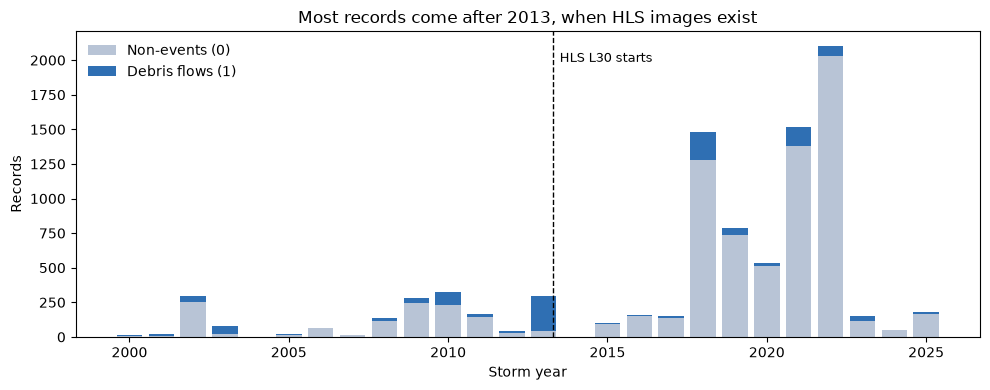

In [4]:
by_year = df.groupby(df["storm"].dt.year)["Response"].agg(total="size", debris_flows="sum")
by_year["non_events"] = by_year["total"] - by_year["debris_flows"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_year.index, by_year["non_events"], label="Non-events (0)", color="#b8c4d6")
ax.bar(by_year.index, by_year["debris_flows"], bottom=by_year["non_events"], label="Debris flows (1)", color="#2f6fb3")
ax.axvline(2013.3, color="black", linestyle="--", linewidth=1)
ax.text(2013.5, ax.get_ylim()[1] * 0.9, "HLS L30 starts", fontsize=9)
ax.set_xlabel("Storm year")
ax.set_ylabel("Records")
ax.set_title("Most records come after 2013, when HLS images exist")
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUT / "records_per_year.png", dpi=150)
plt.show()

## Step 4 · The data funnel

Each step keeps only rows that can still be used. A fire is **usable** only if it has both debris flows and non-events, because a fire with one outcome cannot be scored when it is the test fire.

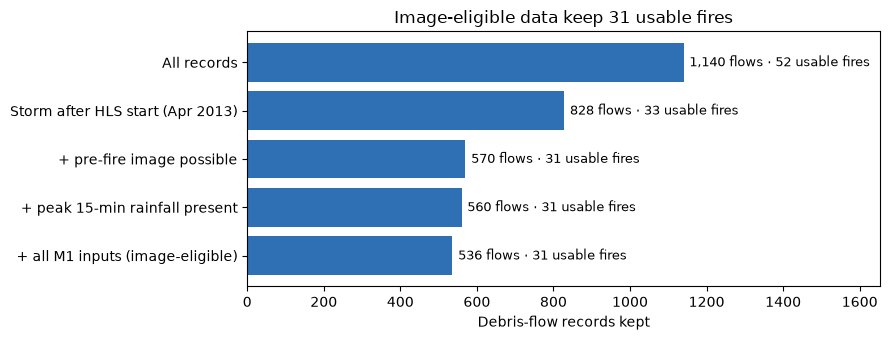

,step,rows,debris_flows,fires,usable_fires
0,All records,8981,1140,80,52
1,Storm after HLS start (Apr 2013),7519,828,48,33
2,+ pre-fire image possible,7220,570,44,31
3,+ peak 15-min rainfall present,6385,560,43,31
4,+ all M1 inputs (image-eligible),6144,536,42,31


In [5]:
def fires_with_both(sub):
    f = sub.groupby("FireName")["Response"].agg(["sum", "count"])
    return int(((f["sum"] > 0) & (f["sum"] < f["count"])).sum())

storm_ok = df["storm"] >= HLS_L30_START
pre_ok = storm_ok & (df["ignition"] >= PRE_FIRE_OK)
i15_ok = pre_ok & df["PeakI15"].notna()
eligible = pre_ok & df[M1_INPUTS].notna().all(axis=1)
df["eligible"] = eligible

steps = [
    ("All records", pd.Series(True, index=df.index)),
    ("Storm after HLS start (Apr 2013)", storm_ok),
    ("+ pre-fire image possible", pre_ok),
    ("+ peak 15-min rainfall present", i15_ok),
    ("+ all M1 inputs (image-eligible)", eligible),
]
funnel = pd.DataFrame([
    {"step": name, "rows": int(m.sum()), "debris_flows": int(df.loc[m, "Response"].sum()),
     "fires": df.loc[m, "FireName"].nunique(), "usable_fires": fires_with_both(df[m])}
    for name, m in steps
])
funnel.to_csv(OUT / "funnel.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(funnel["step"][::-1], funnel["debris_flows"][::-1], color="#2f6fb3")
for i, (flows, fires) in enumerate(zip(funnel["debris_flows"][::-1], funnel["usable_fires"][::-1])):
    ax.text(flows + 15, i, f"{flows:,} flows · {fires} usable fires", va="center", fontsize=9)
ax.set_xlabel("Debris-flow records kept")
ax.set_title("Image-eligible data keep 31 usable fires")
ax.set_xlim(0, funnel["debris_flows"].max() * 1.45)
plt.tight_layout()
fig.savefig(OUT / "funnel.png", dpi=150)
plt.show()
funnel

## Step 5 · Fire-level coverage table

One row per fire. `usable = True` means the fire has image-eligible debris flows **and** non-events. Sort order puts the most useful fires first; use the top 10 for the HLS image check.

In [6]:
cov = df.assign(elig_pos=df["eligible"] & (df["Response"] == 1)).groupby("FireName").agg(
    year=("FireYear", "first"),
    state=("FireState", "first"),
    assessment_id=("AssessmentFireID", "first"),
    records=("Response", "size"),
    debris_flows=("Response", "sum"),
    storm_dates=("StormStart", "nunique"),
    eligible_records=("eligible", "sum"),
    eligible_pos=("elig_pos", "sum"),
    missing_I15=("PeakI15", lambda x: int(x.isna().sum())),
)
cov["eligible_neg"] = cov["eligible_records"] - cov["eligible_pos"]
cov["usable"] = (cov["eligible_pos"] > 0) & (cov["eligible_neg"] > 0)
cov = cov.sort_values(["usable", "eligible_pos"], ascending=False)
cov.to_csv(OUT / "fire_coverage.csv")

usable = cov[cov["usable"]]
print(f"Usable fires: {len(usable)} of {len(cov)}")
usable.head(15)

Usable fires: 31 of 80


,year,state,assessment_id,records,debris_flows,storm_dates,eligible_records,eligible_pos,missing_I15,eligible_neg,usable
FireName,,,,,,,,,,,
Thomas,2017,CA,thm2017,857,171,1,857,171,0,686,True
Dolan,2020,CA,dln2020,118,41,3,118,41,0,77,True
Grizzly Creek,2020,CO,grz2020,2450,50,106,1426,40,830,1386,True
Buzzard,2018,NM,bzz2018,679,26,72,679,26,0,653,True
Ferguson,2018,CA,frg2018,366,28,53,364,26,2,338,True
Cameron Peak,2020,CO,cmp2020,31,21,8,30,20,0,10,True
Cub Creek 2,2021,WA,cub2021,110,19,3,95,18,0,77,True
Tadpole,2020,NM,tad2020,648,16,86,648,16,0,632,True
East Fork,2020,UT,efk2020,28,19,5,23,15,0,8,True


## Step 6 · How concentrated are the debris flows?

If one fire holds a large share of the debris flows, results depend on which fold that fire lands in. This step measures that.

Largest fire: Thomas holds 33% of usable debris flows
Top 3 fires hold 48%
Thomas storm dates: [20180109]

With Thomas:    5,841 records, 520 debris flows, prevalence 0.089
Without Thomas: 4,984 records, 349 debris flows, prevalence 0.070


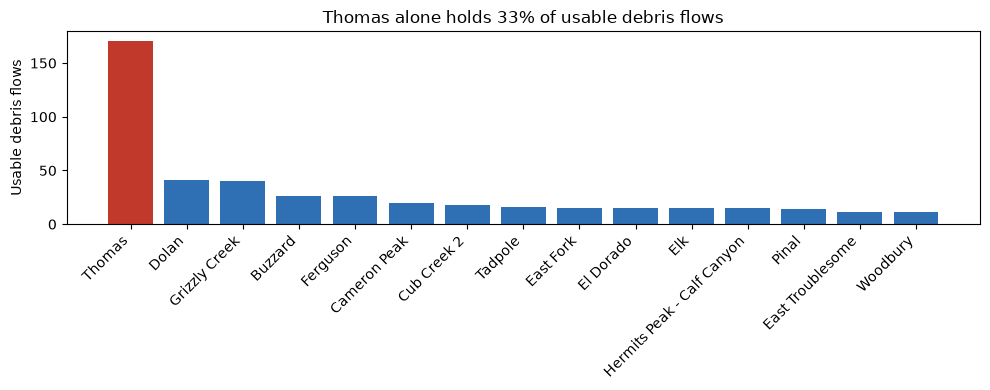

In [7]:
usable_rows = df[df["eligible"] & df["FireName"].isin(usable.index)]
pos_by_fire = usable["eligible_pos"].sort_values(ascending=False)
share = pos_by_fire / pos_by_fire.sum()

print(f"Largest fire: {share.index[0]} holds {share.iloc[0]:.0%} of usable debris flows")
print(f"Top 3 fires hold {share.iloc[:3].sum():.0%}")
thomas_storms = df.loc[df["FireName"] == "Thomas", "StormStart"].unique()
print(f"Thomas storm dates: {thomas_storms}")

no_thomas = usable_rows[usable_rows["FireName"] != "Thomas"]
print(f"\nWith Thomas:    {len(usable_rows):,} records, {int(usable_rows['Response'].sum())} debris flows, "
      f"prevalence {usable_rows['Response'].mean():.3f}")
print(f"Without Thomas: {len(no_thomas):,} records, {int(no_thomas['Response'].sum())} debris flows, "
      f"prevalence {no_thomas['Response'].mean():.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
top = pos_by_fire.head(15)
ax.bar(top.index, top.values, color=["#c0392b" if n == "Thomas" else "#2f6fb3" for n in top.index])
ax.set_ylabel("Usable debris flows")
ax.set_title(f"{share.index[0]} alone holds {share.iloc[0]:.0%} of usable debris flows")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
fig.savefig(OUT / "debris_flows_by_fire.png", dpi=150)
plt.show()

## Step 7 · Basin size compared with one Prithvi token

Prithvi looks at the image in 16 x 16-pixel patches (tokens), about 480 m x 480 m. Basins smaller than one token cannot show internal shape to the model.

Median basin area: 0.151 km² = 0.66 tokens
Basins smaller than one token: 65%
Basins covering 4+ tokens: 18%


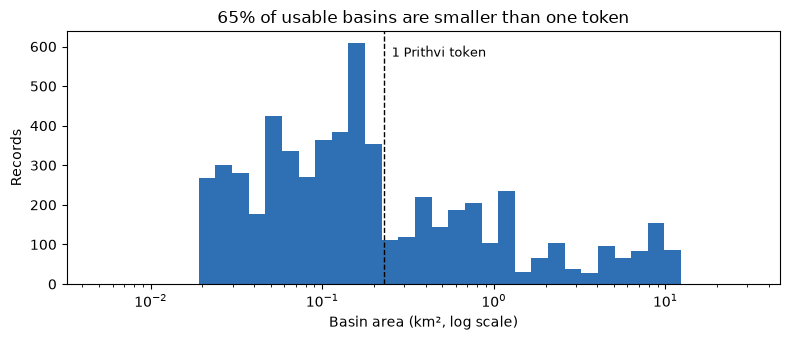

In [8]:
area = usable_rows["UpstreamArea"]
tokens = area / TOKEN_KM2
print(f"Median basin area: {area.median():.3f} km² = {tokens.median():.2f} tokens")
print(f"Basins smaller than one token: {(tokens < 1).mean():.0%}")
print(f"Basins covering 4+ tokens: {(tokens >= 4).mean():.0%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(area[area > 0], bins=pd.Series([0.005 * 1.25 ** i for i in range(40)]), color="#2f6fb3")
ax.axvline(TOKEN_KM2, color="black", linestyle="--", linewidth=1)
ax.text(TOKEN_KM2 * 1.1, ax.get_ylim()[1] * 0.9, "1 Prithvi token", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("Basin area (km², log scale)")
ax.set_ylabel("Records")
ax.set_title(f"{(tokens < 1).mean():.0%} of usable basins are smaller than one token")
plt.tight_layout()
fig.savefig(OUT / "basin_size.png", dpi=150)
plt.show()

## Step 8 · Map of observation points

Blue = usable records, grey = everything else. This is a quick check that the coordinates look sensible (all in the western US).

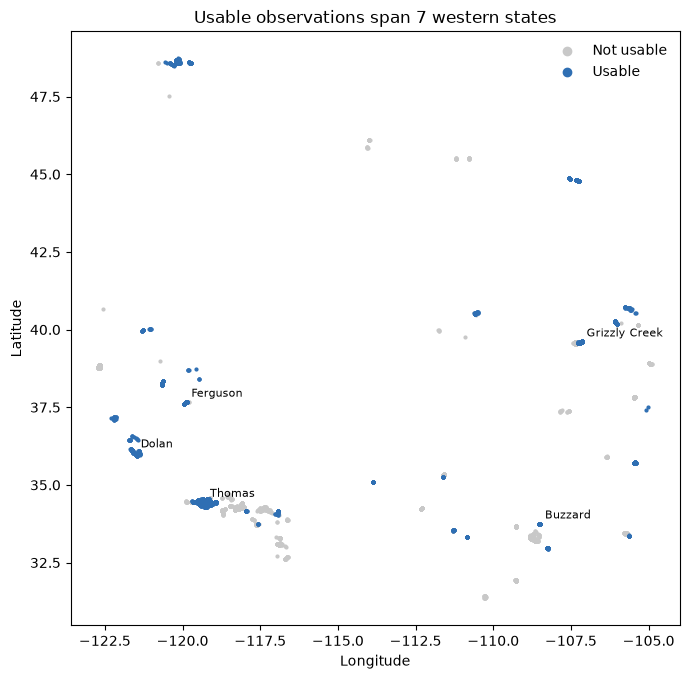

In [9]:
fig, ax = plt.subplots(figsize=(7, 7))
other = df[~df.index.isin(usable_rows.index)]
ax.scatter(other["ObservationLongitude"], other["ObservationLatitude"], s=4, color="#c8c8c8", label="Not usable")
ax.scatter(usable_rows["ObservationLongitude"], usable_rows["ObservationLatitude"], s=4, color="#2f6fb3", label="Usable")
for name in pos_by_fire.head(5).index:
    pt = usable_rows[usable_rows["FireName"] == name][["ObservationLongitude", "ObservationLatitude"]].median()
    ax.annotate(name, pt, fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Usable observations span 7 western states")
ax.set_aspect("equal")
ax.legend(frameon=False, markerscale=3)
plt.tight_layout()
fig.savefig(OUT / "observation_map.png", dpi=150)
plt.show()

## Step 9 · Go / narrow / stop decision (counts only)

The image-availability part of the gate is checked separately (HLS notebook, next week).

In [10]:
n_fires = len(usable)
n_events = int(usable["eligible_pos"].sum())
if n_fires >= GATE["go_fires"] and n_events >= GATE["go_events"]:
    verdict = "GO"
elif n_fires >= GATE["narrow_fires"]:
    verdict = "NARROW"
else:
    verdict = "STOP / RESCOPE"

summary = {
    "usable_fires": n_fires,
    "usable_debris_flows": n_events,
    "usable_records": int(usable["eligible_records"].sum()),
    "prevalence": round(n_events / int(usable["eligible_records"].sum()), 3),
    "largest_fire": share.index[0],
    "largest_fire_share": round(float(share.iloc[0]), 2),
    "median_tokens_per_basin": round(float(tokens.median()), 2),
    "share_basins_below_one_token": round(float((tokens < 1).mean()), 2),
    "verdict_on_counts": verdict,
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))
summary

{'usable_fires': 31,
 'usable_debris_flows': 520,
 'usable_records': 5841,
 'prevalence': 0.089,
 'largest_fire': 'Thomas',
 'largest_fire_share': 0.33,
 'median_tokens_per_basin': 0.66,
 'share_basins_below_one_token': 0.65,
 'verdict_on_counts': 'GO'}

## What to do with these results

- Copy `summary.json` numbers and the four PNG charts into the one-page memo for your advisor.
- Use the top 10 rows of `fire_coverage.csv` for the HLS image check.
- Next notebook: `02_basin_join.ipynb`, which tests whether the USGS hazard-assessment basins join to these records.